# Adult dataset inspection

Exploracao de `adult_train.csv` e `adult_new.csv` antes de configurar a pipeline.

In [28]:
from pathlib import Path
import pandas as pd
from IPython.display import display

data_dirs = [Path("data"), Path("../data")]
data_dir = next((p for p in data_dirs if (p / "adult_train.csv").exists()), None)
if data_dir is None:
    raise FileNotFoundError("Nao encontrei os ficheiros Adult em data/ ou ../data/")

train = pd.read_csv(data_dir / "adult_train.csv")
new = pd.read_csv(data_dir / "adult_new.csv")
print(f"train: {train.shape}")
print(f"new:   {new.shape}")

train: (6000, 41)
new:   (2000, 40)


## Target e estrutura

In [29]:
target = "income_over_50k"
print("Target no train:", target in train.columns)
print("Target no new:  ", target in new.columns)
display(train.head())
display(train.dtypes.rename("dtype").to_frame())
display(train[target].value_counts(normalize=True, dropna=False).mul(100).round(2).rename("percent").to_frame())

Target no train: True
Target no new:   False


,id,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,...,v17,v18,v19,v20,v21,v22,v23,v24,v25,income_over_50k
0,104207,62,Private,174711,HS-grad,9,Never-married,Adm-clerical,Not-in-family,White,...,39,6.135,D18,B19,H20,E21,E22,D23,C24,0
1,104579,53,Private,283320,Bachelors,13,Divorced,Tech-support,Not-in-family,White,...,70,8.940,B18,A19,F20,D21,F22,F23,D24,0
2,103779,25,Private,789600,HS-grad,9,Never-married,Adm-clerical,Unmarried,White,...,24,10.930,F18,B19,E20,C21,F22,F23,A24,0
3,101072,37,Private,139770,HS-grad,9,Never-married,Adm-clerical,Not-in-family,White,...,20,14.070,C18,D19,F20,I21,H22,E23,E24,0
4,102774,22,Private,202153,Some-college,10,Never-married,Adm-clerical,Own-child,White,...,63,1.237,E18,B19,F20,J21,B22,F23,E24,0


,dtype
id,int64
age,int64
workclass,str
fnlwgt,int64
education,str
education_num,int64
marital_status,str
occupation,str
relationship,str
race,str


,percent
income_over_50k,
0,76.07
1,23.93


## Missing values e placeholders

In [30]:
def missing_report(df):
    report = pd.DataFrame({
        "nulls": df.isna().sum(),
        "question_marks": (df.astype("object") == "?").sum(),
        "empty_strings": (df.astype("object") == "").sum(),
    })
    report["missing_like"] = report.sum(axis=1)
    return report.sort_values("missing_like", ascending=False)

print("TRAIN")
display(missing_report(train).query("missing_like > 0"))
print("NEW")
display(missing_report(new).query("missing_like > 0"))

TRAIN


,nulls,question_marks,empty_strings,missing_like
occupation,0,381,0,381
workclass,0,379,0,379
v02,206,0,0,206
v03,201,0,0,201
v05,185,0,0,185
v06,178,0,0,178
v04,177,0,0,177
v01,169,0,0,169
native_country,0,86,0,86


NEW


,nulls,question_marks,empty_strings,missing_like
occupation,0,112,0,112
workclass,0,111,0,111
v01,69,0,0,69
v02,64,0,0,64
v06,60,0,0,60
v05,58,0,0,58
v04,55,0,0,55
v03,47,0,0,47
native_country,0,35,0,35


In [31]:
for column in ["workclass", "occupation", "native_country"]:
    print(f"\n{column} - train")
    display(train[column].value_counts(dropna=False).head(15).to_frame("count"))
    print(f"{column} - new")
    display(new[column].value_counts(dropna=False).head(15).to_frame("count"))


workclass - train


,count
workclass,
Private,4081
Self-emp-not-inc,490
Local-gov,416
?,379
State-gov,260
Self-emp-inc,206
Federal-gov,163
Without-pay,3
Never-worked,2


workclass - new


,count
workclass,
Private,1404
Self-emp-not-inc,141
Local-gov,121
?,111
State-gov,79
Self-emp-inc,72
Federal-gov,70
Never-worked,1
Without-pay,1



occupation - train


,count
occupation,
Prof-specialty,782
Craft-repair,741
Exec-managerial,707
Sales,699
Adm-clerical,658
Other-service,620
?,381
Machine-op-inspct,366
Transport-moving,281


... (2 outputs left out)


native_country - train


,count
native_country,
United-States,5389
Mexico,137
?,86
Philippines,44
Germany,24
El-Salvador,21
Puerto-Rico,20
Cuba,20
Canada,19


native_country - new


,count
native_country,
United-States,1788
Mexico,39
?,35
Cuba,15
India,12
Germany,11
Philippines,11
Portugal,8
Iran,6


## Cardinalidade e duplicados

In [32]:
summary = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "n_unique": train.nunique(dropna=False),
    "missing": train.isna().sum(),
})
display(summary.sort_values(["dtype", "n_unique"]))

for name, df in [("train", train), ("new", new)]:
    print(name, "duplicate rows:", int(df.duplicated().sum()), "duplicate ids:", int(df["id"].duplicated().sum()))

,dtype,n_unique,missing
v03,float64,12,201
v05,float64,101,185
v01,float64,3028,169
v13,float64,3030,0
v07,float64,3075,0
v04,float64,3778,177
v10,float64,3907,0
v16,float64,3909,0
v02,float64,4418,206
v06,float64,4431,178


train duplicate rows: 0 duplicate ids: 0
new duplicate rows: 0 duplicate ids: 0


## Matriz de correlacoes numericas

A correlacao de Pearson so pode ser calculada diretamente nas colunas numericas. Valores perto de `1` ou `-1` indicam uma relacao linear forte; isto nao prova causalidade nem significa, sozinho, que uma coluna deva ser removida.

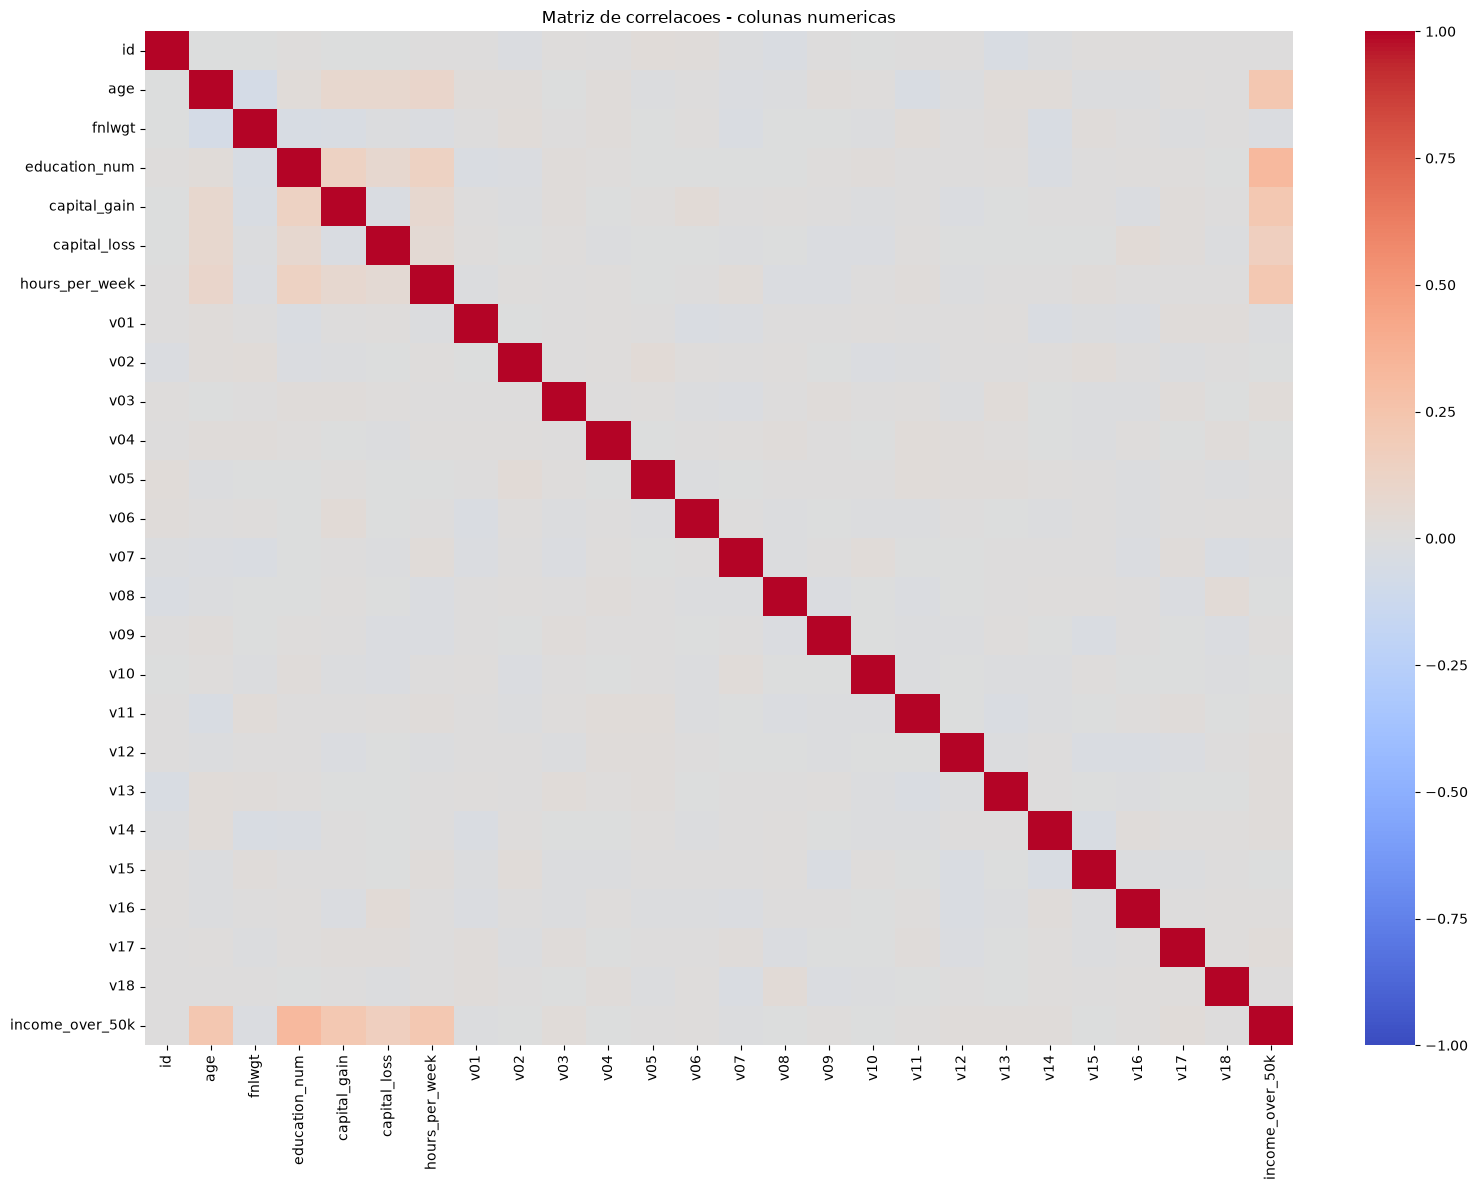

Correlacoes com o target, ordenadas por valor absoluto:


,correlation
education_num,0.326163
age,0.231374
hours_per_week,0.222338
capital_gain,0.221750
capital_loss,0.159365
v17,0.030153
v03,0.025281
fnlwgt,-0.018927
v14,0.016729
v12,0.016227


Pares de features com |correlacao| >= 0.80:


,,correlation,abs_correlation


In [33]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

numeric = train.select_dtypes(include="number").copy()
correlations = numeric.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(correlations, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matriz de correlacoes - colunas numericas")
plt.tight_layout()
plt.show()

print("Correlacoes com o target, ordenadas por valor absoluto:")
target_correlations = correlations[target].drop(target).dropna()
target_correlations = target_correlations.reindex(target_correlations.abs().sort_values(ascending=False).index)
display(target_correlations.to_frame("correlation"))

print("Pares de features com |correlacao| >= 0.80:")
upper = correlations.where(~np.tril(np.ones(correlations.shape), k=0).astype(bool))
strong_pairs = (
    upper.stack()
    .rename("correlation")
    .to_frame()
    .assign(abs_correlation=lambda df: df["correlation"].abs())
    .query("abs_correlation >= 0.80")
    .sort_values("abs_correlation", ascending=False)
)
display(strong_pairs)


## Diagnostico de missingness e MNAR

Esta analise verifica todas as colunas que possuem `NaN`, string vazia ou `?`. Uma diferenca grande na taxa de `income_over_50k` entre linhas missing e nao-missing indica uma candidata a MNAR. O limite abaixo e apenas um filtro de diagnostico, nao uma prova causal.

In [34]:
min_rate_difference = 0.05
mnar_rows = []

for column in train.columns:
    if column == target:
        continue

    values = train[column].astype("string")
    missing = values.isna() | values.str.strip().isin(["?", ""])

    missing_count = int(missing.sum())
    if missing_count == 0 or missing_count == len(train):
        continue

    missing_rate = train.loc[missing, target].mean()
    observed_rate = train.loc[~missing, target].mean()
    difference = missing_rate - observed_rate

    mnar_rows.append({
        "column": column,
        "missing_count": missing_count,
        "missing_percent": round(missing.mean() * 100, 2),
        "target_rate_missing": round(missing_rate, 4),
        "target_rate_observed": round(observed_rate, 4),
        "difference": round(difference, 4),
        "absolute_difference": round(abs(difference), 4),
        "candidate_MNAR": abs(difference) >= min_rate_difference,
    })

mnar_report = pd.DataFrame(mnar_rows).sort_values(
    "absolute_difference", ascending=False
)
display(mnar_report)

print("\nColunas candidatas a MNAR pelo limite escolhido:")
display(mnar_report.query("candidate_MNAR"))


,column,missing_count,missing_percent,target_rate_missing,target_rate_observed,difference,absolute_difference,candidate_MNAR
1,occupation,381,6.35,0.1234,0.2472,-0.1238,0.1238,True
0,workclass,379,6.32,0.1240,0.2471,-0.1231,0.1231,True
8,v06,178,2.97,0.1854,0.2410,-0.0556,0.0556,True
6,v04,177,2.95,0.2712,0.2384,0.0328,0.0328,False
3,v01,169,2.82,0.2604,0.2387,0.0216,0.0216,False
2,native_country,86,1.43,0.2326,0.2394,-0.0069,0.0069,False
7,v05,185,3.08,0.2432,0.2392,0.0040,0.0040,False
4,v02,206,3.43,0.2379,0.2394,-0.0015,0.0015,False
5,v03,201,3.35,0.2388,0.2394,-0.0005,0.0005,False



Colunas candidatas a MNAR pelo limite escolhido:


,column,missing_count,missing_percent,target_rate_missing,target_rate_observed,difference,absolute_difference,candidate_MNAR
1,occupation,381,6.35,0.1234,0.2472,-0.1238,0.1238,True
0,workclass,379,6.32,0.1240,0.2471,-0.1231,0.1231,True
8,v06,178,2.97,0.1854,0.2410,-0.0556,0.0556,True


## Features sugeridas para `config_adult.yaml`

- Target: `income_over_50k`.
- Excluir: `id`, `fnlwgt`, `education`.
- Escolher `sex` como `sensitive_attr`; nesse caso `sex` nao deve ser feature.
- Numericas: `age`, `education_num`, `capital_gain`, `capital_loss`, `hours_per_week`, `v01` a `v18`.
- Categoricas: `workclass`, `marital_status`, `occupation`, `relationship`, `race`, `v19` a `v25`.
- Transformar `?` em missing real em `workclass`, `occupation` e `native_country`.
- Usar indicadores de missingness para `workclass` e `occupation`.
- Nao transformar `capital_gain = 99999` em missing.
- Usar `adult_train.csv` na cross-validation e `adult_new.csv` apenas para prever no fim.

In [35]:
target = "income_over_50k"

feature_candidates = train.drop(columns=[target], errors="ignore")

summary = pd.DataFrame({
    "dtype": feature_candidates.dtypes,
    "unique_values": feature_candidates.nunique(dropna=False),
    "missing_percent": feature_candidates.isna().mean().mul(100).round(2),
})

display(summary.sort_values(["unique_values", "missing_percent"]))

,dtype,unique_values,missing_percent
sex,str,2,0.00
v20,str,4,0.00
race,str,5,0.00
relationship,str,6,0.00
v24,str,6,0.00
v25,str,6,0.00
marital_status,str,7,0.00
v19,str,7,0.00
v21,str,8,0.00
workclass,str,9,0.00


In [36]:
constant = summary[summary["unique_values"] <= 1]
almost_constant = summary[summary["unique_values"] <= 2]

print("Constantes:")
display(constant)

print("Com no máximo 2 valores:")
display(almost_constant)

Constantes:


,dtype,unique_values,missing_percent


Com no máximo 2 valores:


,dtype,unique_values,missing_percent
sex,str,2,0.0


In [37]:
categorical_columns = train.select_dtypes(exclude="number").columns

for column in categorical_columns:
    print(f"\n{column}")
    print(train[column].value_counts(dropna=False).head(20))


workclass
workclass
Private             4081
Self-emp-not-inc     490
Local-gov            416
?                    379
State-gov            260
Self-emp-inc         206
Federal-gov          163
Without-pay            3
Never-worked           2
Name: count, dtype: int64

education
education
HS-grad         1907
Some-college    1291
Bachelors       1009
Masters          342
11th             240
Assoc-voc        239
Assoc-acdm       203
10th             182
7th-8th          110
Prof-school      106
9th               94
12th              81
5th-6th           80
Doctorate         73
1st-4th           32
Preschool         11
Name: count, dtype: int64

marital_status
marital_status
Married-civ-spouse       2780
Never-married            1999
Divorced                  799
Widowed                   181
Separated                 165
Married-spouse-absent      73
Married-AF-spouse           3
Name: count, dtype: int64

occupation
occupation
Prof-specialty       782
Craft-repair         741
Exec-

In [38]:
pd.crosstab(train["education"], train["education_num"])

education_num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
education,,,,,,,,,,,,,,,,
10th,0,0,0,0,0,182,0,0,0,0,0,0,0,0,0,0
11th,0,0,0,0,0,0,240,0,0,0,0,0,0,0,0,0
12th,0,0,0,0,0,0,0,81,0,0,0,0,0,0,0,0
1st-4th,0,32,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5th-6th,0,0,80,0,0,0,0,0,0,0,0,0,0,0,0,0
7th-8th,0,0,0,110,0,0,0,0,0,0,0,0,0,0,0,0
9th,0,0,0,0,94,0,0,0,0,0,0,0,0,0,0,0
Assoc-acdm,0,0,0,0,0,0,0,0,0,0,0,203,0,0,0,0
Assoc-voc,0,0,0,0,0,0,0,0,0,0,239,0,0,0,0,0


In [39]:
categorical_columns = train.select_dtypes(exclude="number").columns

for column in categorical_columns:
    values = train[column].dropna().astype(str)

    normalized = values.str.strip().str.lower()

    variants = (
        pd.DataFrame({"original": values, "normalized": normalized})
        .drop_duplicates()
        .sort_values("normalized")
    )

    duplicated_normalized = (
        variants.groupby("normalized")["original"]
        .nunique()
        .loc[lambda x: x > 1]
    )

    if len(duplicated_normalized) > 0:
        print(f"\n{column}: possíveis categorias equivalentes")
        display(variants[variants["normalized"].isin(duplicated_normalized.index)])

In [40]:
for column in categorical_columns:
    count = (train[column].astype("object") == "?").sum()
    if count > 0:
        print(column, count)

workclass 379
occupation 381
native_country 86


In [41]:
for column in ["workclass", "occupation", "native_country"]:
    missing = train[column].isna() | train[column].eq("?")

    comparison = train.groupby(missing)["income_over_50k"].agg(
        n="size",
        mean_target="mean"
    )

    comparison["percent_target"] = comparison["mean_target"].mul(100).round(2)

    print(f"\n{column}")
    display(comparison)


workclass


,n,mean_target,percent_target
workclass,,,
False,5621,0.247109,24.71
True,379,0.124011,12.40



occupation


,n,mean_target,percent_target
occupation,,,
False,5619,0.247197,24.72
True,381,0.123360,12.34



native_country


,n,mean_target,percent_target
native_country,,,
False,5914,0.239432,23.94
True,86,0.232558,23.26
